# Data exploration (first look at the raw sources)

A quick tour of the raw files before preprocessing: what the Steam metadata tables contain, what a five-minute player history looks like, and how Twitch attention lines up with Steam players for one game. The final analysis does not depend on this notebook.

In [1]:
from pathlib import Path
import csv

import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

PROJECT_ROOT = Path.cwd().resolve()
while not (PROJECT_ROOT / "data").exists() and PROJECT_ROOT != PROJECT_ROOT.parent:
    PROJECT_ROOT = PROJECT_ROOT.parent
STEAM_DIR = PROJECT_ROOT / "data" / "steam-games-dataset"
SULLY_DIR = PROJECT_ROOT / "data" / "sullygnome"


def read_multi(filename, column):
    """Wide 'appid,value1,value2,...' files; csv.reader keeps quoted values such as "Psyonix, Inc." whole."""
    with (STEAM_DIR / filename).open(encoding="cp1252", newline="") as file:
        rows = [(int(r[0]), v.strip()) for r in csv.reader(file) if r and r[0].isdigit() for v in r[1:] if v.strip()]
    return pd.DataFrame(rows, columns=["appid", column])


application_info = pd.read_csv(STEAM_DIR / "applicationInformation.csv", encoding="cp1252")
tables = {
    "developer": read_multi("applicationDevelopers.csv", "developer"),
    "genre": read_multi("applicationGenres.csv", "genre"),
    "package": read_multi("applicationPackages.csv", "package"),
    "publisher": read_multi("applicationPublishers.csv", "publisher"),
    "language": read_multi("applicationSupportedlanguages.csv", "language"),
    "tag": read_multi("applicationTags.csv", "tag"),
}
display(application_info.head(10))
for column, table in tables.items():
    print(f"{column:>10}: {len(table):>6,} rows, {table[column].nunique():>5,} distinct values, "
          f"top: {', '.join(table[column].value_counts().head(3).index)}")

,appid,type,name,releasedate,freetoplay
0,578080,game,PLAYERUNKNOWN'S BATTLEGROUNDS,21-Dec-17,0.0
1,570,game,Dota 2,9-Jul-13,1.0
2,730,game,Counter-Strike: Global Offensive,21-Aug-12,1.0
3,622590,NaN,PLAYERUNKNOWN'S BATTLEGROUNDS (Test Server),NaN,NaN
4,359550,game,Tom Clancy's Rainbow Six Siege,1-Dec-15,0.0
5,271590,game,Grand Theft Auto V,13-Apr-15,0.0
6,238960,game,Path of Exile,23-Oct-13,1.0
7,230410,game,Warframe,25-Mar-13,1.0
8,440,game,Team Fortress 2,10-Oct-07,1.0
9,252950,game,Rocket League,7-Jul-15,0.0


 developer:  2,154 rows, 1,330 distinct values, top: Feral Interactive (Mac), Valve, Feral Interactive (Linux)
     genre:  4,830 rows,    26 distinct values, top: Action, Indie, Adventure
   package:  2,431 rows, 2,256 distinct values, top: 116764, 123985, 4323
 publisher:  2,047 rows,   919 distinct values, top: Ubisoft, SEGA, Feral Interactive (Mac)
  language: 12,025 rows,    31 distinct values, top: English, German, French
       tag: 29,013 rows,   339 distinct values, top: Singleplayer, Action, Adventure


## Five-minute player histories

Four very different games: a battle royale at its peak (PUBG), a single-player RPG (The Witcher 3), a multiplayer survival game that left Early Access in Feb 2018 (Rust) and a free-to-play MOBA (Dota 2).

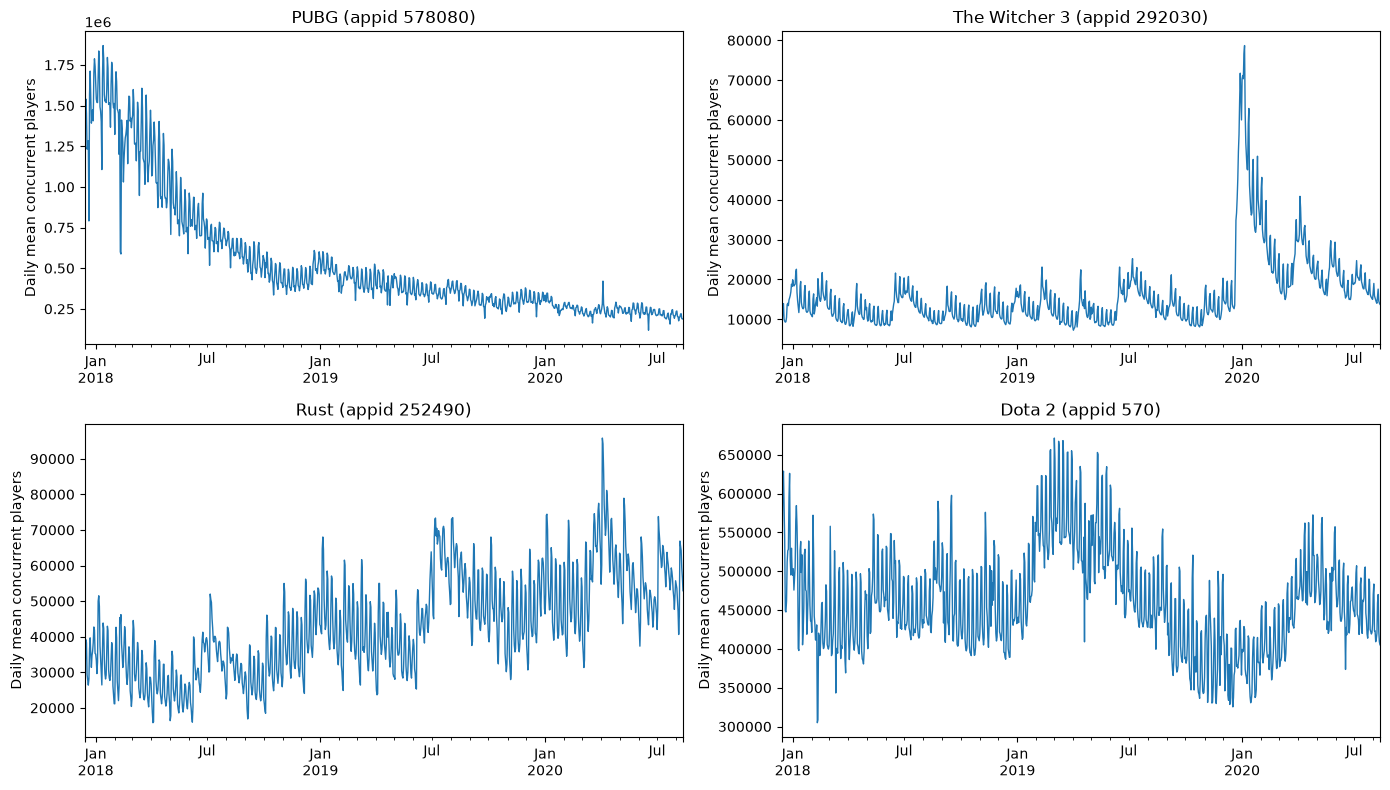

In [2]:
def history_path(appid):
    for part in ("PlayerCountHistoryPart1", "PlayerCountHistoryPart2"):
        path = STEAM_DIR / part / f"{appid}.csv"
        if path.exists():
            return path
    raise FileNotFoundError(f"No player-count history for appid {appid}")


EXAMPLE_GAMES = {578080: "PUBG", 292030: "The Witcher 3", 252490: "Rust", 570: "Dota 2"}
fig, axes = plt.subplots(2, 2, figsize=(14, 8))
for ax, (appid, name) in zip(axes.ravel(), EXAMPLE_GAMES.items()):
    history = pd.read_csv(history_path(appid), parse_dates=["Time"], index_col="Time")["Playercount"]
    history.resample("D").mean().plot(ax=ax, lw=1)
    ax.set_title(f"{name} (appid {appid})")
    ax.set_xlabel("")
    ax.set_ylabel("Daily mean concurrent players")
fig.tight_layout()
plt.show()

## Steam players vs. Twitch viewers

`twitch_monthly_by_appid.csv` is produced by `data-preprocessing/twitch-mapping.ipynb`.

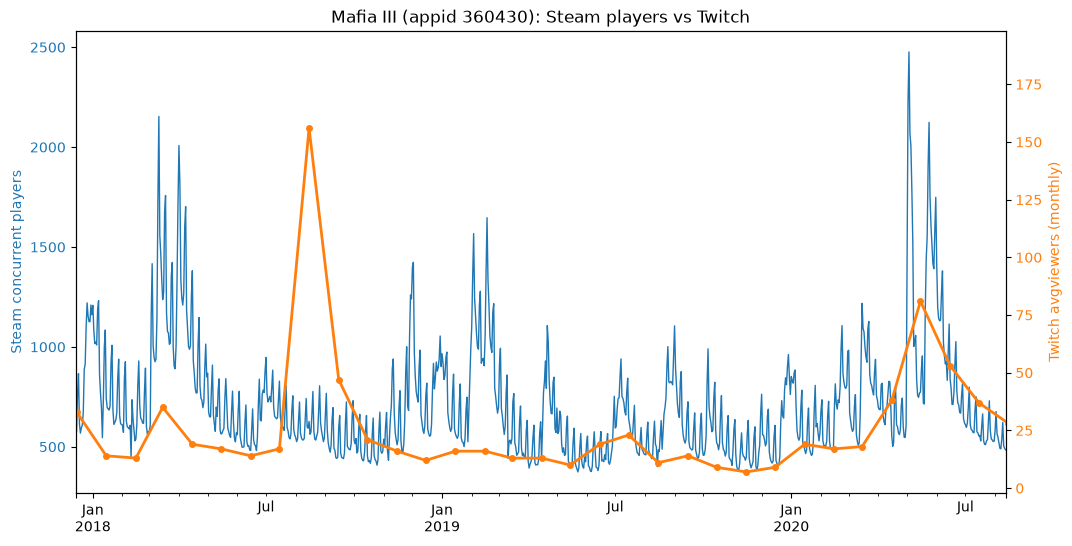

In [3]:
twitch = pd.read_csv(SULLY_DIR / "twitch_monthly_by_appid.csv", parse_dates=["month"])


def plot_game(appid, metric="avgviewers", ax=None):
    players = pd.read_csv(history_path(appid), parse_dates=["Time"], index_col="Time")["Playercount"]
    game_twitch = twitch[twitch["appid"] == appid].set_index("month")[metric].sort_index()
    name = twitch.loc[twitch["appid"] == appid, "name_steam"].iloc[0]

    ax = ax or plt.subplots(figsize=(12, 6))[1]
    players.resample("D").mean().plot(ax=ax, color="tab:blue", lw=1)
    ax.set_ylabel("Steam concurrent players", color="tab:blue")
    ax.tick_params(axis="y", labelcolor="tab:blue")
    ax.set_xlabel("")
    twin = ax.twinx()
    twin.plot(game_twitch.index + pd.Timedelta(days=14), game_twitch.values, color="tab:orange", lw=2, marker="o", ms=4)
    twin.set_ylabel(f"Twitch {metric} (monthly)", color="tab:orange")
    twin.tick_params(axis="y", labelcolor="tab:orange")
    twin.set_xlim(ax.get_xlim())
    ax.set_title(f"{name} (appid {appid}): Steam players vs Twitch")
    return ax


plot_game(360430)
plt.show()